# KMeans lexical path: is the k-search's concave/unimodal assumption valid?

**Purpose:** `clustering/kmeans.py`'s k-search (`_search_kmeans_k`) does a coarse-to-fine
*recursive narrowing* search over k, guided by a custom score
(`silhouette_score + (1 - k/n)`). That search strategy implicitly assumes the score is a
well-behaved, single-peaked (concave/unimodal) function of k. This notebook checks that
assumption directly.

- **Containment principle:** everything here is implemented from scratch in
  `notebooks/diagnostics.py` using raw sklearn primitives (`CountVectorizer`/
  `TfidfVectorizer`, `TruncatedSVD`, `KMeans`, `silhouette_score`) with parameters this
  notebook controls explicitly. It does **not** import `clustering/kmeans.py` or `app.py`,
  because those modules' current choices are exactly what's under question here.
- Findings here are the *input* to implementing `clustering/kmeans.py`.


In [1]:
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
from diagnostics import aggregate_by_user, vectorize, sweep_k, count_local_maxima, smooth_curve_shape

with open("../data/stackoverflow_sample_2021_03_01_n5000.json") as f:
    df_n5000 = pd.DataFrame(json.load(f))
with open("../data/stackoverflow_sample_2021_03_01_n5000_repeat_users.json") as f:
    df_repeat = pd.DataFrame(json.load(f))

print(f"n5000: {len(df_n5000)} rows, {df_n5000['user_id'].nunique()} distinct users")
print(f"repeat_users: {len(df_repeat)} rows, {df_repeat['user_id'].nunique()} distinct users, "
      f"max rows/user = {df_repeat['user_id'].value_counts().max()}")


n5000: 5000 rows, 4789 distinct users
repeat_users: 387 rows, 176 distinct users, max rows/user = 5


## Data matrix

Two field types, matching the two use cases the app's config actually supports:

- **`tags` + count vectorizer** -- a small, mostly-discrete categorical vocabulary.
- **`title` + TF-IDF** -- continuous natural language.

Two scale/shape variants -- `n5000` is the full raw sample. The real second variant is **aggregation**, which
does change the shape of the problem: `n5000` has only 176 users with >1 row out of 4789
distinct users, so join-field aggregation on it barely changes anything. `repeat_users`
is `n5000` filtered down to exactly those 176 repeat users (387 rows, all users with 2-5
rows), giving a genuine aggregated-scale test rather than a redundant raw-sample size.


In [2]:
variants = {
    "tags/count, n5000 raw": (df_n5000["tags"], "count"),
    "titles/tfidf, n5000 raw": (df_n5000["title"], "tfidf"),
    "tags/count, repeat_users aggregated": (aggregate_by_user(df_repeat, "tags"), "count"),
    "titles/tfidf, repeat_users aggregated": (aggregate_by_user(df_repeat, "title"), "tfidf"),
}
for name, (values, method) in variants.items():
    print(f"{name}: {len(values)} rows, method={method}")


tags/count, n5000 raw: 5000 rows, method=count
titles/tfidf, n5000 raw: 5000 rows, method=tfidf
tags/count, repeat_users aggregated: 176 rows, method=count
titles/tfidf, repeat_users aggregated: 176 rows, method=tfidf


## Sweeping k

An **independent, evenly-spaced sweep** over k for each variant -- not the production
search's adaptive/greedy trajectory, which would only sample points the heuristic itself
chose to look at, which is exactly the assumption being checked. `n_components=30` is
used throughout for comparability across variants.


In [3]:
k_ranges = {
    "tags/count, n5000 raw": range(2, 400, 8),
    "titles/tfidf, n5000 raw": range(2, 400, 8),
    "tags/count, repeat_users aggregated": range(2, 80, 2),
    "titles/tfidf, repeat_users aggregated": range(2, 80, 2),
}

sweeps = {}
shape_summary = []
for name, (values, method) in variants.items():
    vect, _ = vectorize(values, method, n_components=30)
    sweep = sweep_k(vect, k_ranges[name])
    sweeps[name] = sweep

    sil_best_idx = sweep["silhouette"].idxmax()
    heur_best_idx = sweep["heuristic"].idxmax()
    shape_summary.append({
        "variant": name,
        "n_points_swept": len(sweep),
        "raw_local_maxima": count_local_maxima(sweep["silhouette"].values),
        "silhouette_best_k": int(sweep.loc[sil_best_idx, "k"]),
        "silhouette_best_val": round(float(sweep.loc[sil_best_idx, "silhouette"]), 3),
        "heuristic_best_k": int(sweep.loc[heur_best_idx, "k"]),
        "heuristic_best_val": round(float(sweep.loc[heur_best_idx, "heuristic"]), 3),
    })

shape_df = pd.DataFrame(shape_summary)
shape_df


,variant,n_points_swept,raw_local_maxima,silhouette_best_k,silhouette_best_val,heuristic_best_k,heuristic_best_val
0,"tags/count, n5000 raw",50,12,82,0.762,82,1.745
1,"titles/tfidf, n5000 raw",50,16,394,0.114,2,1.102
2,"tags/count, repeat_users aggregated",39,9,62,0.407,26,1.208
3,"titles/tfidf, repeat_users aggregated",39,12,66,0.096,2,1.044


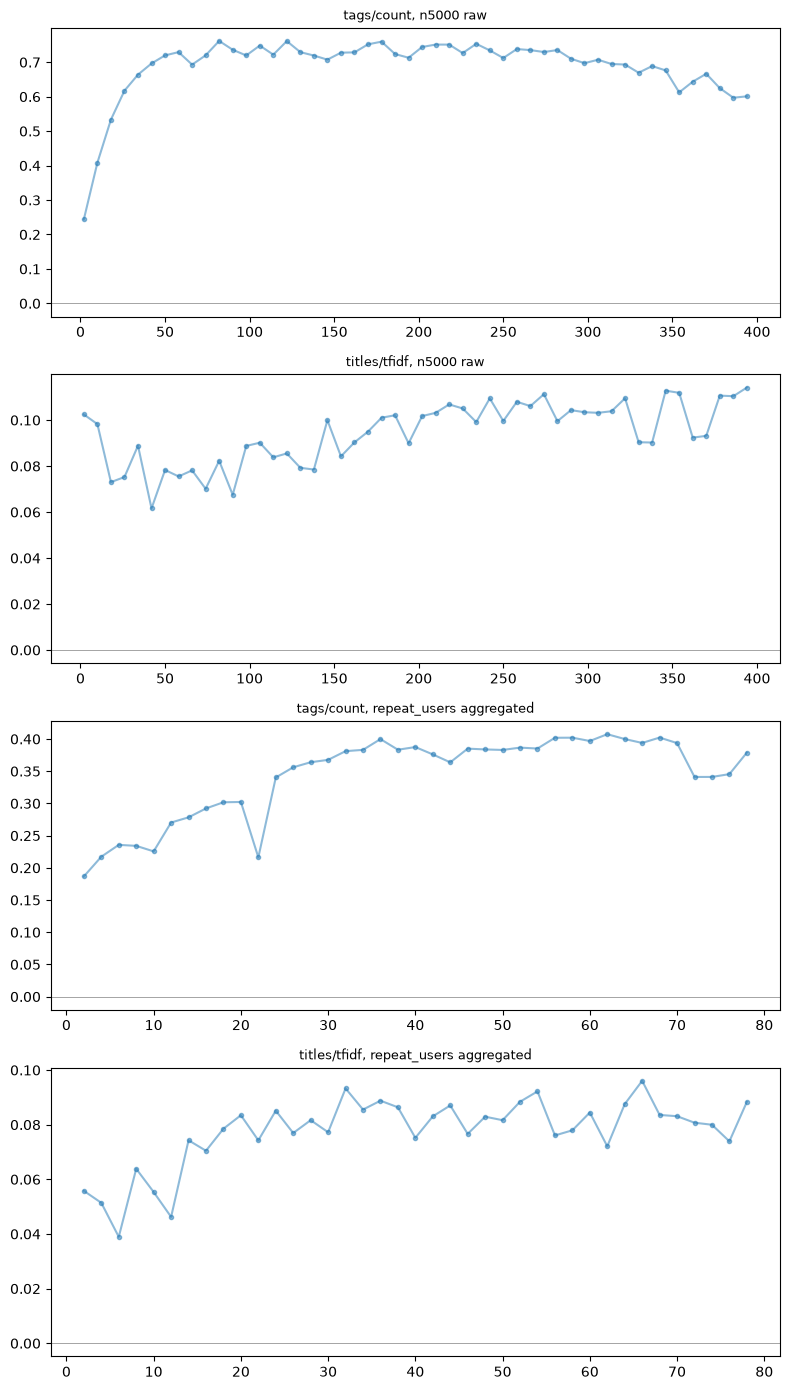

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(8, 14))
for ax, (name, sweep) in zip(axes, sweeps.items()):
    ax.plot(sweep["k"], sweep["silhouette"], marker=".", alpha=0.5, label="raw silhouette")
    ax.set_title(name, fontsize=9)
    ax.axhline(0, color="gray", linewidth=0.5)
fig.tight_layout()
plt.show()


### Is "many local maxima" real structure or noise?

A rigorous test, not an eyeballed one: how much variance a plain two-parameter
**parabola** explains (a parabola can only ever have one peak or one valley, so this is a
direct concavity test), and how much deliberate smoothing a proper smoothing spline needs
before it collapses to a single true peak.


In [5]:
shape_tests = []
for name, sweep in sweeps.items():
    result = smooth_curve_shape(sweep["k"].values, sweep["silhouette"].values)
    shape_tests.append({
        "variant": name,
        "parabola_r2": result["parabola_r2"],
        "unimodal_at_s_mult": result["unimodal_at"]["s_mult"] if result["unimodal_at"] else None,
        "r2_at_unimodal": result["unimodal_at"]["r2"] if result["unimodal_at"] else None,
    })
shape_test_df = pd.DataFrame(shape_tests)
shape_test_df


,variant,parabola_r2,unimodal_at_s_mult,r2_at_unimodal
0,"tags/count, n5000 raw",0.585,2,0.900
1,"titles/tfidf, n5000 raw",0.509,5,0.750
2,"tags/count, repeat_users aggregated",0.878,2,0.900
3,"titles/tfidf, repeat_users aggregated",0.647,10,0.693


### Also: does titles/tfidf have real structure anywhere, over a much wider k range?

The sweep above only goes to k=400 for `n5000`. Checking whether silhouette is trending
toward a real peak outside that window, or is just uniformly weak everywhere.


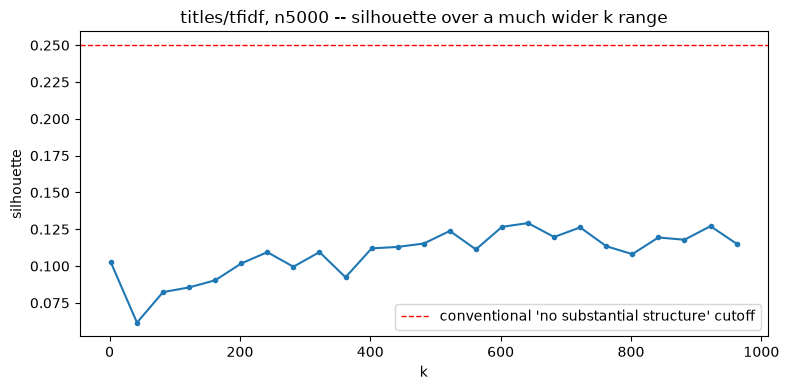

max silhouette across k=2..962: 0.129


In [6]:
vect_titles, _ = vectorize(df_n5000["title"], "tfidf", n_components=30)
sweep_wide = sweep_k(vect_titles, range(2, 1000, 40))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep_wide["k"], sweep_wide["silhouette"], marker=".")
ax.axhline(0.25, color="red", linestyle="--", linewidth=1, label="conventional 'no substantial structure' cutoff")
ax.set_xlabel("k")
ax.set_ylabel("silhouette")
ax.set_title("titles/tfidf, n5000 -- silhouette over a much wider k range")
ax.legend()
fig.tight_layout()
plt.show()
print("max silhouette across k=2..962:", round(sweep_wide['silhouette'].max(), 3))


### Observations

**For `tags/count` (the path being kept), the underlying trend genuinely is close to a
single smooth concave function -- the raw multi-peak counts were overwhelmingly noise.**
A plain parabola already explains the majority of the variance in the curve, and only
*mild* smoothing is enough to collapse it to exactly one true peak. The concave/unimodal
shape the original k-search was designed around genuinely holds for this field type, once
noise is properly accounted for.

**For `titles/tfidf`, it doesn't.** A parabola explains notably less of the curve, and
reaching a single peak needs more aggressive smoothing that discards more of the actual
fit. Combined with silhouette staying uniformly weak (never exceeding ~0.13, well under
the conventional 0.25 "no substantial structure" cutoff) across an extremely wide k range
(tested to k=962), this points to a different diagnosis than "genuinely complex
multi-modal structure": there just isn't a strong real trend here to fit in the first
place. No k-search strategy, however robust to multi-modality, would find a good k here,
because the underlying geometry doesn't contain one.

**The heuristic's `(1 - k/n)` penalty term does its intended job on `tags/count`,
pulling the chosen k down from the raw-silhouette peak toward a simpler solution while
staying in a comparably strong-quality region.** On `titles/tfidf`, where there's no real
signal, the penalty term dominates the score instead and produces near-meaningless
answers like k=2, where the "score" is almost entirely `1 - 2/n`. That's a symptom of the
field type having no real structure, not a flaw in the heuristic itself.


## Conclusions for `clustering/kmeans.py` (input to phase 2)

1. **Drop TF-IDF + KMeans for free text; keep it for count-vectorized categorical
   fields only.** Silhouette stays uniformly weak across an extremely wide k range, and
   the score-vs-k curve doesn't fit a smooth trend well even under aggressive smoothing --
   both point to an absence of real cluster structure, not a search-difficulty problem.
   The "lexical path" should be scoped to genuinely discrete/structured fields; free text
   is the semantic path's job (embeddings + BERTopic), not a stretched version of the
   lexical one.

2. **Keep the current k-search approach for the count/categorical path as
   implemented.** The concave/unimodal assumption it was built on genuinely holds here --
   this isn't a case that needs a redesign. A good follow-up, not needed urgently:
   visually confirm the production search's actual chosen k lands near the true peak
   found independently in this notebook, as direct evidence the implemented algorithm
   performs well in practice, not just that the underlying shape supports it in theory.

3. **Keep the heuristic (`silhouette + (1 - k/n)`) as designed.** Not just because it
   behaves reasonably on structured data -- there's a clear product reason to want it:
   fewer clusters make the human review step in the app faster and easier, and when the
   achievable quality difference is negligible, trading a small amount of raw silhouette
   for a meaningfully smaller review burden is the right call, not a compromise.
